In [66]:
try:
    import pandas as pd
    print('Install pandas successfully',pd.__version__)
except ImportError:
    print('Install pandas failed')

try:
    from IPython.display import display
    print('Install display successfully')
except ImportError:
    print('Install display failed')
    
try:
    import matplotlib.pyplot as plt
    print('Install matplotlib successfully')
except ImportError:
    print('Install matplotlib failed')
    
try:
    import seaborn as sns
    print('Install seaborn successfully')
except ImportError:
    print('Install seaborn failed')

Install pandas successfully 3.0.5
Install display successfully
Install matplotlib successfully
Install seaborn successfully


In [67]:
#Self study 23/9/2026 - Get data
Categories_2 = '/Users/phatpeso/Desktop/Phat/Python/Data Mining/data/raw/self_study/Categories_2.csv'
Countries_2 = '/Users/phatpeso/Desktop/Phat/Python/Data Mining/data/raw/self_study/Countries_2.csv'
Products_2 = '/Users/phatpeso/Desktop/Phat/Python/Data Mining/data/raw/self_study/Products_2.csv'
sales_data_2 = '/Users/phatpeso/Desktop/Phat/Python/Data Mining/data/raw/self_study/sales_data_2.csv'
States_2 = '/Users/phatpeso/Desktop/Phat/Python/Data Mining/data/raw/self_study/States_2.csv'
SubCategories_2 = '/Users/phatpeso/Desktop/Phat/Python/Data Mining/data/raw/self_study/SubCategories_2.csv'
try:
    sale_df = pd.read_csv(sales_data_2)
    products_df = pd.read_csv(Products_2)
    categories_df = pd.read_csv(Categories_2)
    countries_df = pd.read_csv(Countries_2)
    states_df = pd.read_csv(States_2)
    subcategories_df = pd.read_csv(SubCategories_2)
    print('Get all data successfully')
except NameError:
    print('Get data failed')

Get all data successfully


In [68]:
# Review data
print('Review sales_data')
display(sale_df.head(5))

print('Review Products')
display(products_df.head(5))

print('Review categories')
display(categories_df.head(5))

print('Review SubCategories')
display(subcategories_df.head(5))

print('Review Countries')
display(countries_df.head(5))

print('Review States')
display(states_df.head(5))

Review sales_data


,SaleID,CustomerName,ProductID,StateID,Quantity,TotalAmount_USD,Date
0,1,Linda Rodriguez,1055,1,3,2320.20,2025-01-01 00:00:00
1,2,Michael Anderson,1002,17,2,4767.84,2025-01-01 01:00:00
2,3,Mary Martin,1062,11,1,904.48,2025-01-01 02:00:00
3,4,Barbara Smith,1091,19,2,4399.04,2025-01-01 03:00:00
4,5,Linda Jones,1021,3,1,1765.30,2025-01-01 04:00:00


Review Products


,ProductID,ProductName,SubCategoryID,Price_USD
0,1001,iPad Titanium (SKU-100),109,844.44
1,1002,iPhone SE Titanium (SKU-101),114,2383.92
2,1003,Apple Watch Series 9 512GB (SKU-102),116,2606.59
3,1004,AirPods Pro 2 256GB (SKU-103),118,1863.61
4,1005,Apple Watch Ultra 2 Starlight (SKU-104),115,1568.83


Review categories


...

,SubCategoryID,CategoryID,SubCategoryName
0,101,1,MacBook Air
1,102,1,MacBook Pro
2,103,1,iMac
3,104,1,Mac mini
4,105,1,Mac Studio


Review Countries


,CountryID,CountryName
0,1,Vietnam
1,2,Thailand
2,3,Indonesia
3,4,Malaysia
4,5,Singapore


Review States


,StateID,CountryID,StateName
0,1,1,Hanoi
1,2,1,Ho Chi Minh City
2,3,1,Da Nang
3,4,2,Bangkok
4,5,2,Chiang Mai


** Yêu cầu: Đọc file Products_2.csv. 
Sắp xếp dữ liệu theo cột Price_USD giảm dần và in ra 5 dòng đầu tiên (chỉ hiển thị cột ProductName và Price_USD).

In [69]:
# Processing
sorted_products = products_df.sort_values(by='Price_USD',ascending=False)
top_5_products = sorted_products[['ProductName','Price_USD']].head(5)

print('Top 5 products:')
display(top_5_products)


Top 5 products:


,ProductName,Price_USD
99,Apple Watch Ultra 2 Midnight (SKU-199),2894.08
37,AirTag Wi-Fi (SKU-137),2875.24
48,iPhone 15 512GB (SKU-148),2862.11
16,Mac Studio Midnight (SKU-116),2831.92
59,iPhone 15 Titanium (SKU-159),2814.70


Mục tiêu: Đếm xem sản phẩm (ProductName) nào bán được số lượng (Quantity) nhiều nhất.
Yêu cầu: Kết nối (Merge) bảng sales_data_2.csv và Products_2.csv. Sau đó dùng groupby theo ProductName để tính tổng cột Quantity. In ra Top 3 sản phẩm bán chạy nhất về mặt số lượng.

In [70]:
#Merge
megre_df = pd.merge(sale_df,products_df, on='ProductID', how='inner').reset_index()

total_products = megre_df.groupby('ProductName')['Quantity'].sum().reset_index()

top_3_products = total_products.sort_values(by='Quantity', ascending= False).head(3)

print('Top 3 products')
display(top_3_products)

Top 3 products


,ProductName,Quantity
32,Apple Watch Series 9 1TB (SKU-120),88
22,Apple Pencil Wi-Fi (SKU-146),77
60,MagSafe Charger Titanium (SKU-118),72


Thử thách 3: Nâng cao (Xử lý thời gian và Trực quan hóa)
- Mục tiêu: Xem doanh thu ngày nào cao nhất trong tháng 1/2025.
Yêu cầu:
- Tính cột doanh thu (TotalAmount_USD = Price_USD * Quantity).
- Chuyển đổi cột Date sang định dạng datetime bằng pd.to_datetime().
- Rút trích phần ngày (không lấy giờ) hoặc dùng .dt.date.
- Gom nhóm theo ngày và tính tổng doanh thu.
- (Tùy chọn) Dùng Matplotlib hoặc Seaborn vẽ một biểu đồ đường (Line chart) thể hiện biến động doanh thu theo ngày.

,OnlyDay,Quantity
0,2025-01-01,52
1,2025-01-02,60
2,2025-01-03,65
3,2025-01-04,51
4,2025-01-05,59
...,...,...
70,2025-03-12,66
71,2025-03-13,55
72,2025-03-14,58
73,2025-03-15,61


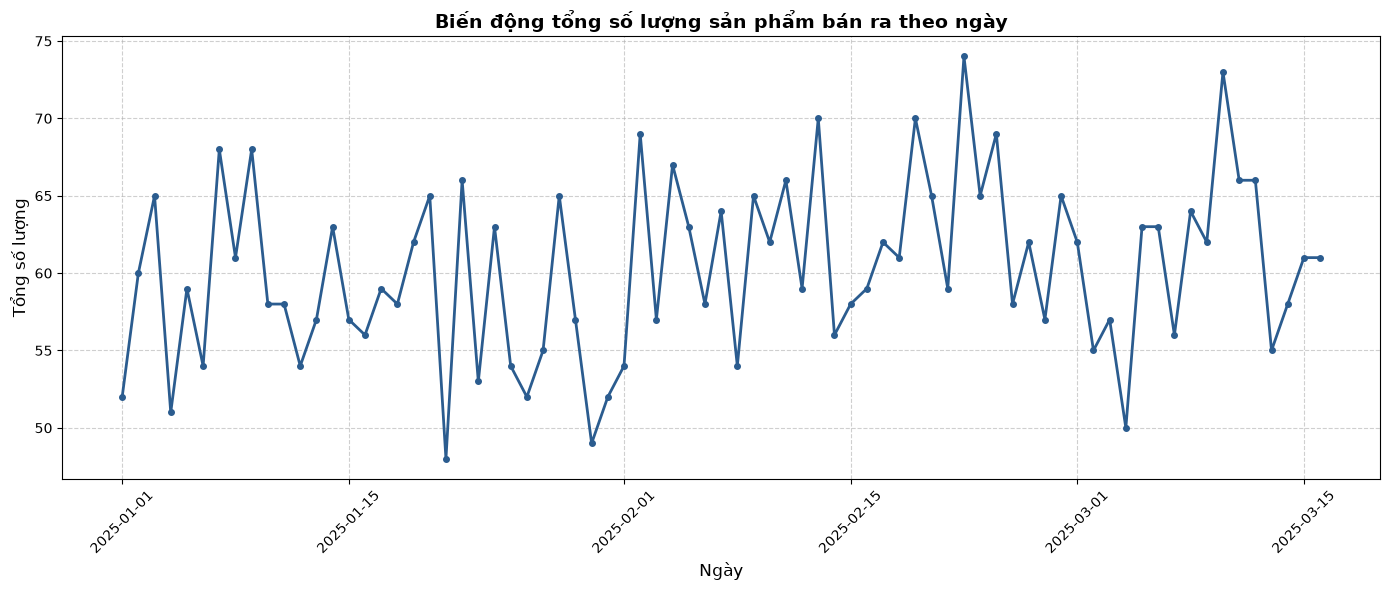

In [71]:
#Processing
megre_df['TotalAmount_USD'] = megre_df['Price_USD']*megre_df['Quantity']
megre_df['Date'] = pd.to_datetime(megre_df['Date'])
megre_df['OnlyDay'] = megre_df['Date'].dt.date
day_sales = megre_df.groupby('OnlyDay')['Quantity'].sum().reset_index()
display(day_sales)
#drawing
plt.figure(figsize=(14,6))
plt.plot(day_sales['OnlyDay'],day_sales['Quantity'],marker = 'o', color = '#2b5c8f', linewidth = 2, markersize = 4)
plt.title('Biến động tổng số lượng sản phẩm bán ra theo ngày',fontsize = 14, fontweight = 'bold')
plt.xlabel('Ngày',fontsize = 12)
plt.ylabel('Tổng số lượng',fontsize = 12)
plt.xticks(rotation = 45)

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Practice


In [72]:
display(sale_df.head(5))
display(states_df.head(5))
display(countries_df.head(5))

,SaleID,CustomerName,ProductID,StateID,Quantity,TotalAmount_USD,Date
0,1,Linda Rodriguez,1055,1,3,2320.20,2025-01-01 00:00:00
1,2,Michael Anderson,1002,17,2,4767.84,2025-01-01 01:00:00
2,3,Mary Martin,1062,11,1,904.48,2025-01-01 02:00:00
3,4,Barbara Smith,1091,19,2,4399.04,2025-01-01 03:00:00
4,5,Linda Jones,1021,3,1,1765.30,2025-01-01 04:00:00


,StateID,CountryID,StateName
0,1,1,Hanoi
1,2,1,Ho Chi Minh City
2,3,1,Da Nang
3,4,2,Bangkok
4,5,2,Chiang Mai


,CountryID,CountryName
0,1,Vietnam
1,2,Thailand
2,3,Indonesia
3,4,Malaysia
4,5,Singapore


### Kết hợp (merge) bảng sales_data_2.csv, States_2.csv và Countries_2.csv

In [73]:
practice_merge_df = pd.merge(sale_df,states_df, on='StateID',how='inner')
print('Merge sale table and State table:')
display(practice_merge_df.head(5))

practice_merge_df = pd.merge(practice_merge_df,countries_df, on ='CountryID', how= 'inner')
print('Merge sale table, State table and Country table:')
display(practice_merge_df.head(5))

Merge sale table and State table:


,SaleID,CustomerName,ProductID,StateID,Quantity,TotalAmount_USD,Date,CountryID,StateName
0,1,Linda Rodriguez,1055,1,3,2320.20,2025-01-01 00:00:00,1,Hanoi
1,2,Michael Anderson,1002,17,2,4767.84,2025-01-01 01:00:00,7,Yangon
2,3,Mary Martin,1062,11,1,904.48,2025-01-01 02:00:00,4,Penang
3,4,Barbara Smith,1091,19,2,4399.04,2025-01-01 03:00:00,8,Phnom Penh
4,5,Linda Jones,1021,3,1,1765.30,2025-01-01 04:00:00,1,Da Nang


Merge sale table, State table and Country table:


,SaleID,CustomerName,ProductID,StateID,Quantity,TotalAmount_USD,Date,CountryID,StateName,CountryName
0,1,Linda Rodriguez,1055,1,3,2320.20,2025-01-01 00:00:00,1,Hanoi,Vietnam
1,2,Michael Anderson,1002,17,2,4767.84,2025-01-01 01:00:00,7,Yangon,Myanmar
2,3,Mary Martin,1062,11,1,904.48,2025-01-01 02:00:00,4,Penang,Malaysia
3,4,Barbara Smith,1091,19,2,4399.04,2025-01-01 03:00:00,8,Phnom Penh,Cambodia
4,5,Linda Jones,1021,3,1,1765.30,2025-01-01 04:00:00,1,Da Nang,Vietnam


### Gom nhóm theo CountryName và tính:
- Tổng doanh thu (sum của TotalAmount_USD).   
- Số lượng sản phẩm trung bình trên mỗi đơn hàng (mean của Quantity).   
- Tổng số đơn hàng thực hiện (count của SaleID).   

In [74]:
country_sale = practice_merge_df.groupby('CountryName')['TotalAmount_USD'].sum().reset_index().sort_values(by='TotalAmount_USD',ascending= False)
print('Total amount for each country')
display(country_sale.head(10))

Total amount for each country


,CountryName,TotalAmount_USD
10,Vietnam,896406.60
4,Malaysia,889374.44
6,Philippines,866489.68
2,Indonesia,847706.02
8,Thailand,774927.95
5,Myanmar,596414.10
1,Cambodia,510134.70
3,Laos,492722.81
7,Singapore,314715.94
0,Brunei,300741.65


In [75]:
average_quantitly_country = practice_merge_df.groupby('CountryName')['Quantity'].mean().reset_index().sort_values(by='Quantity', ascending= False)
print('Average Quantity for each country')
display(average_quantitly_country)

Average Quantity for each country


,CountryName,Quantity
0,Brunei,2.690141
9,Timor-Leste,2.579710
1,Cambodia,2.576389
10,Vietnam,2.576271
6,Philippines,2.540084
8,Thailand,2.511962
4,Malaysia,2.504425
3,Laos,2.492754
2,Indonesia,2.463964
7,Singapore,2.372093


In [76]:
sale_performance_country = practice_merge_df.groupby('CountryName')['SaleID'].count().reset_index().sort_values(by='SaleID',ascending=False)
print('Total sale performance: ')
display(sale_performance_country)

Total sale performance: 


,CountryName,SaleID
6,Philippines,237
10,Vietnam,236
4,Malaysia,226
2,Indonesia,222
8,Thailand,209
5,Myanmar,162
1,Cambodia,144
3,Laos,138
7,Singapore,86
0,Brunei,71


### Mục tiêu: Phân loại các đơn hàng thành các phân khúc giá trị để biết đơn hàng tầm trung, cao cấp chiếm tỷ lệ thế nào.
#### Yêu cầu:
- Sử dụng cột TotalAmount_USD trong bảng sales_data_2.csv.
- Dùng pd.cut() để chia giá trị đơn hàng thành 3 nhóm:   
    - Low: Từ $0 đến $1,000.   
    - Medium: Từ $1,000 đến $4,000.   
    - High: Từ $4,000 đến $15,000.   
- Đếm số lượng đơn hàng rơi vào từng nhóm và in ra màn hình tỷ lệ phần trăm tương ứng.

In [77]:
practice_merge_df['Amount Status'] = pd.cut(practice_merge_df['TotalAmount_USD'],bins=[0,1000,4000,15000], labels=['Low','Medium','High'])
status_percent = practice_merge_df['Amount Status'].value_counts()
status_percent = status_percent.reset_index()
status_percent.columns = ['Status', 'Total']
status_percent['Percent'] = status_percent['Total']/len(practice_merge_df['Amount Status'])*100
print('Proportio of status')
display(status_percent)

Proportio of status


,Status,Total,Percent
0,Medium,905,50.277778
1,High,676,37.555556
2,Low,219,12.166667


### Mục tiêu: So sánh doanh thu giữa các Danh mục chính (CategoryName) trên từng Quốc gia (CountryName).
#### Yêu cầu:
- Merge đầy đủ các bảng để có một bảng tổng hợp chứa cả CategoryName, CountryName và TotalAmount_USD.   

- Sử dụng hàm pd.pivot_table():   

- Dòng (index): CountryName.   

- Cột (columns): CategoryName.   

- Giá trị (values): TotalAmount_USD.   

- Hàm tính toán (aggfunc): tính tổng (sum).   

- Điền giá trị 0 vào các ô bị trống (NaN) nếu có bằng tham số fill_value=0.

In [78]:
print('Category table:')
display(categories_df.head(10))

print('SubCategory table:')
display(subcategories_df.head(10))

print('Country table:')
display(countries_df.head(10))

print('State table:')
display(states_df.head(10))

print('Products table:')
display(products_df.head(10))

print('Sale table: ')
display(sale_df.head(10))

Category table:


,CategoryID,CategoryName
0,1,Mac
1,2,iPad
2,3,iPhone
3,4,Watch
4,5,AirPods
5,6,Accessories


SubCategory table:


,SubCategoryID,CategoryID,SubCategoryName
0,101,1,MacBook Air
1,102,1,MacBook Pro
2,103,1,iMac
3,104,1,Mac mini
4,105,1,Mac Studio
5,106,2,iPad Pro
6,107,2,iPad Air
7,108,2,iPad mini
8,109,2,iPad
9,110,3,iPhone 15 Pro Max


Country table:


...

,StateID,CountryID,StateName
0,1,1,Hanoi
1,2,1,Ho Chi Minh City
2,3,1,Da Nang
3,4,2,Bangkok
4,5,2,Chiang Mai
5,6,2,Phuket
6,7,3,Jakarta
7,8,3,Bali
8,9,3,Surabaya
9,10,4,Kuala Lumpur


Products table:


,ProductID,ProductName,SubCategoryID,Price_USD
0,1001,iPad Titanium (SKU-100),109,844.44
1,1002,iPhone SE Titanium (SKU-101),114,2383.92
2,1003,Apple Watch Series 9 512GB (SKU-102),116,2606.59
3,1004,AirPods Pro 2 256GB (SKU-103),118,1863.61
4,1005,Apple Watch Ultra 2 Starlight (SKU-104),115,1568.83
5,1006,iPhone 15 Titanium (SKU-105),111,560.98
6,1007,iPad mini Midnight (SKU-106),108,282.02
7,1008,Apple Watch SE Midnight (SKU-107),117,440.18
8,1009,AirPods Max 1TB (SKU-108),119,758.34
9,1010,iPhone 15 Pro Max 1TB (SKU-109),110,1089.86


Sale table: 


,SaleID,CustomerName,ProductID,StateID,Quantity,TotalAmount_USD,Date
0,1,Linda Rodriguez,1055,1,3,2320.20,2025-01-01 00:00:00
1,2,Michael Anderson,1002,17,2,4767.84,2025-01-01 01:00:00
2,3,Mary Martin,1062,11,1,904.48,2025-01-01 02:00:00
3,4,Barbara Smith,1091,19,2,4399.04,2025-01-01 03:00:00
4,5,Linda Jones,1021,3,1,1765.30,2025-01-01 04:00:00
5,6,Joseph Smith,1079,11,1,2368.82,2025-01-01 05:00:00
6,7,James Martinez,1021,5,1,1765.30,2025-01-01 06:00:00
7,8,Elizabeth Anderson,1010,17,1,1089.86,2025-01-01 07:00:00
8,9,Thomas Garcia,1087,22,4,2957.32,2025-01-01 08:00:00
9,10,John Gonzalez,1058,7,2,905.80,2025-01-01 09:00:00


In [79]:
practice_merge_df = pd.merge(practice_merge_df,products_df, on='ProductID', how='inner')
display(practice_merge_df.head(10))


,SaleID,CustomerName,ProductID,StateID,Quantity,TotalAmount_USD,Date,CountryID,StateName,CountryName,Amount Status,ProductName,SubCategoryID,Price_USD
0,1,Linda Rodriguez,1055,1,3,2320.20,2025-01-01 00:00:00,1,Hanoi,Vietnam,Medium,Apple Watch Ultra 2 Midnight (SKU-154),115,773.40
1,2,Michael Anderson,1002,17,2,4767.84,2025-01-01 01:00:00,7,Yangon,Myanmar,High,iPhone SE Titanium (SKU-101),114,2383.92
2,3,Mary Martin,1062,11,1,904.48,2025-01-01 02:00:00,4,Penang,Malaysia,Low,Apple Watch Ultra 2 512GB (SKU-161),115,904.48
3,4,Barbara Smith,1091,19,2,4399.04,2025-01-01 03:00:00,8,Phnom Penh,Cambodia,High,iPhone 14 Cellular (SKU-190),112,2199.52
4,5,Linda Jones,1021,3,1,1765.30,2025-01-01 04:00:00,1,Da Nang,Vietnam,Medium,Apple Watch Series 9 1TB (SKU-120),116,1765.30
5,6,Joseph Smith,1079,11,1,2368.82,2025-01-01 05:00:00,4,Penang,Malaysia,Medium,iPhone SE Wi-Fi (SKU-178),114,2368.82
6,7,James Martinez,1021,5,1,1765.30,2025-01-01 06:00:00,2,Chiang Mai,Thailand,Medium,Apple Watch Series 9 1TB (SKU-120),116,1765.30
7,8,Elizabeth Anderson,1010,17,1,1089.86,2025-01-01 07:00:00,7,Yangon,Myanmar,Medium,iPhone 15 Pro Max 1TB (SKU-109),110,1089.86
8,9,Thomas Garcia,1087,22,4,2957.32,2025-01-01 08:00:00,9,Luang Prabang,Laos,Medium,Apple Watch SE Midnight (SKU-186),117,739.33
9,10,John Gonzalez,1058,7,2,905.80,2025-01-01 09:00:00,3,Jakarta,Indonesia,Low,iPad 256GB (SKU-157),109,452.90


In [80]:
practice_merge_df = pd.merge(practice_merge_df,subcategories_df, on='SubCategoryID', how= 'inner')
display(practice_merge_df.head(10))

,SaleID,CustomerName,ProductID,StateID,Quantity,TotalAmount_USD,Date,CountryID,StateName,CountryName,Amount Status,ProductName,SubCategoryID,Price_USD,CategoryID,SubCategoryName
0,1,Linda Rodriguez,1055,1,3,2320.20,2025-01-01 00:00:00,1,Hanoi,Vietnam,Medium,Apple Watch Ultra 2 Midnight (SKU-154),115,773.40,4,Apple Watch Ultra 2
1,2,Michael Anderson,1002,17,2,4767.84,2025-01-01 01:00:00,7,Yangon,Myanmar,High,iPhone SE Titanium (SKU-101),114,2383.92,3,iPhone SE
2,3,Mary Martin,1062,11,1,904.48,2025-01-01 02:00:00,4,Penang,Malaysia,Low,Apple Watch Ultra 2 512GB (SKU-161),115,904.48,4,Apple Watch Ultra 2
3,4,Barbara Smith,1091,19,2,4399.04,2025-01-01 03:00:00,8,Phnom Penh,Cambodia,High,iPhone 14 Cellular (SKU-190),112,2199.52,3,iPhone 14
4,5,Linda Jones,1021,3,1,1765.30,2025-01-01 04:00:00,1,Da Nang,Vietnam,Medium,Apple Watch Series 9 1TB (SKU-120),116,1765.30,4,Apple Watch Series 9
5,6,Joseph Smith,1079,11,1,2368.82,2025-01-01 05:00:00,4,Penang,Malaysia,Medium,iPhone SE Wi-Fi (SKU-178),114,2368.82,3,iPhone SE
6,7,James Martinez,1021,5,1,1765.30,2025-01-01 06:00:00,2,Chiang Mai,Thailand,Medium,Apple Watch Series 9 1TB (SKU-120),116,1765.30,4,Apple Watch Series 9
7,8,Elizabeth Anderson,1010,17,1,1089.86,2025-01-01 07:00:00,7,Yangon,Myanmar,Medium,iPhone 15 Pro Max 1TB (SKU-109),110,1089.86,3,iPhone 15 Pro Max
8,9,Thomas Garcia,1087,22,4,2957.32,2025-01-01 08:00:00,9,Luang Prabang,Laos,Medium,Apple Watch SE Midnight (SKU-186),117,739.33,4,Apple Watch SE
9,10,John Gonzalez,1058,7,2,905.80,2025-01-01 09:00:00,3,Jakarta,Indonesia,Low,iPad 256GB (SKU-157),109,452.90,2,iPad


In [81]:
practice_merge_df = pd.merge(practice_merge_df,categories_df,on='CategoryID', how='inner')
display(practice_merge_df.head(10))

,SaleID,CustomerName,ProductID,StateID,Quantity,TotalAmount_USD,Date,CountryID,StateName,CountryName,Amount Status,ProductName,SubCategoryID,Price_USD,CategoryID,SubCategoryName,CategoryName
0,1,Linda Rodriguez,1055,1,3,2320.20,2025-01-01 00:00:00,1,Hanoi,Vietnam,Medium,Apple Watch Ultra 2 Midnight (SKU-154),115,773.40,4,Apple Watch Ultra 2,Watch
1,2,Michael Anderson,1002,17,2,4767.84,2025-01-01 01:00:00,7,Yangon,Myanmar,High,iPhone SE Titanium (SKU-101),114,2383.92,3,iPhone SE,iPhone
2,3,Mary Martin,1062,11,1,904.48,2025-01-01 02:00:00,4,Penang,Malaysia,Low,Apple Watch Ultra 2 512GB (SKU-161),115,904.48,4,Apple Watch Ultra 2,Watch
3,4,Barbara Smith,1091,19,2,4399.04,2025-01-01 03:00:00,8,Phnom Penh,Cambodia,High,iPhone 14 Cellular (SKU-190),112,2199.52,3,iPhone 14,iPhone
4,5,Linda Jones,1021,3,1,1765.30,2025-01-01 04:00:00,1,Da Nang,Vietnam,Medium,Apple Watch Series 9 1TB (SKU-120),116,1765.30,4,Apple Watch Series 9,Watch
5,6,Joseph Smith,1079,11,1,2368.82,2025-01-01 05:00:00,4,Penang,Malaysia,Medium,iPhone SE Wi-Fi (SKU-178),114,2368.82,3,iPhone SE,iPhone
6,7,James Martinez,1021,5,1,1765.30,2025-01-01 06:00:00,2,Chiang Mai,Thailand,Medium,Apple Watch Series 9 1TB (SKU-120),116,1765.30,4,Apple Watch Series 9,Watch
7,8,Elizabeth Anderson,1010,17,1,1089.86,2025-01-01 07:00:00,7,Yangon,Myanmar,Medium,iPhone 15 Pro Max 1TB (SKU-109),110,1089.86,3,iPhone 15 Pro Max,iPhone
8,9,Thomas Garcia,1087,22,4,2957.32,2025-01-01 08:00:00,9,Luang Prabang,Laos,Medium,Apple Watch SE Midnight (SKU-186),117,739.33,4,Apple Watch SE,Watch
9,10,John Gonzalez,1058,7,2,905.80,2025-01-01 09:00:00,3,Jakarta,Indonesia,Low,iPad 256GB (SKU-157),109,452.90,2,iPad,iPad


In [82]:
pivot_table = pd.pivot_table(practice_merge_df,index='CountryName',columns='CategoryName',values='TotalAmount_USD', aggfunc = 'sum').fillna(0)
print('Pivot table Country name and Category name: ')
display(pivot_table)

Pivot table Country name and Category name: 


CategoryName,Accessories,AirPods,Mac,Watch,iPad,iPhone
CountryName,,,,,,
Brunei,71696.32,33387.31,50777.61,80618.17,20484.34,43777.90
Cambodia,73736.89,82829.69,107529.11,100222.50,22110.61,123705.90
Indonesia,104952.87,106490.60,160226.79,242315.19,64533.32,169187.25
Laos,76747.44,67047.40,95877.75,105685.57,50290.73,97073.92
Malaysia,131766.69,132117.81,193361.96,177439.10,93495.90,161192.98
Myanmar,74375.58,103291.24,138349.62,128786.20,59778.77,91832.69
Philippines,168652.98,114364.56,224122.52,158223.26,61251.69,139874.67
Singapore,50746.89,45628.74,54388.85,57031.77,41065.45,65854.24
Thailand,143584.79,110386.20,131995.21,153711.34,66644.52,168605.89


### Mục tiêu: Tìm hiểu xem khách hàng Đông Nam Á hay mua sắm đồ Apple vào ngày nào trong tuần nhất.
#### Yêu cầu:
- Trích xuất thứ trong tuần từ cột Date thành một cột mới tên là DayOfWeek bằng thuộc tính .dt.day_name().
- Gom nhóm theo DayOfWeek và tính tổng doanh thu.   
- Sắp xếp lại thứ tự các ngày theo chuẩn từ Thứ Hai đến Chủ Nhật (Monday -> Sunday).
- (Tùy chọn) Dùng thư viện seaborn.barplot để vẽ biểu đồ so sánh doanh thu giữa các thứ trong tuần.

In [101]:
practice_merge_df['Date'] = pd.to_datetime(practice_merge_df['Date'])
practice_merge_df['Day Of Week'] = practice_merge_df['Date'].dt.day_name()
day_of_week_sale = practice_merge_df.groupby(by='Day Of Week')['TotalAmount_USD'].count().reset_index().sort_index()
display(day_of_week_sale)

,Day Of Week,TotalAmount_USD
0,Friday,264
1,Monday,240
2,Saturday,264
3,Sunday,264
4,Thursday,264
5,Tuesday,240
6,Wednesday,264


In [102]:
DayOfWeek = ['Monday', 'Tuesday', 'Wednesday', 'Thursday','Friday', 'Saturday', 'Sunday']
day_of_week_sale['Day Of Week'] = pd.Categorical(day_of_week_sale['Day Of Week'],categories=DayOfWeek,ordered=True)
day_of_week_sale = day_of_week_sale.sort_values(by='Day Of Week')
display(day_of_week_sale)

,Day Of Week,TotalAmount_USD
1,Monday,240
5,Tuesday,240
6,Wednesday,264
4,Thursday,264
0,Friday,264
2,Saturday,264
3,Sunday,264


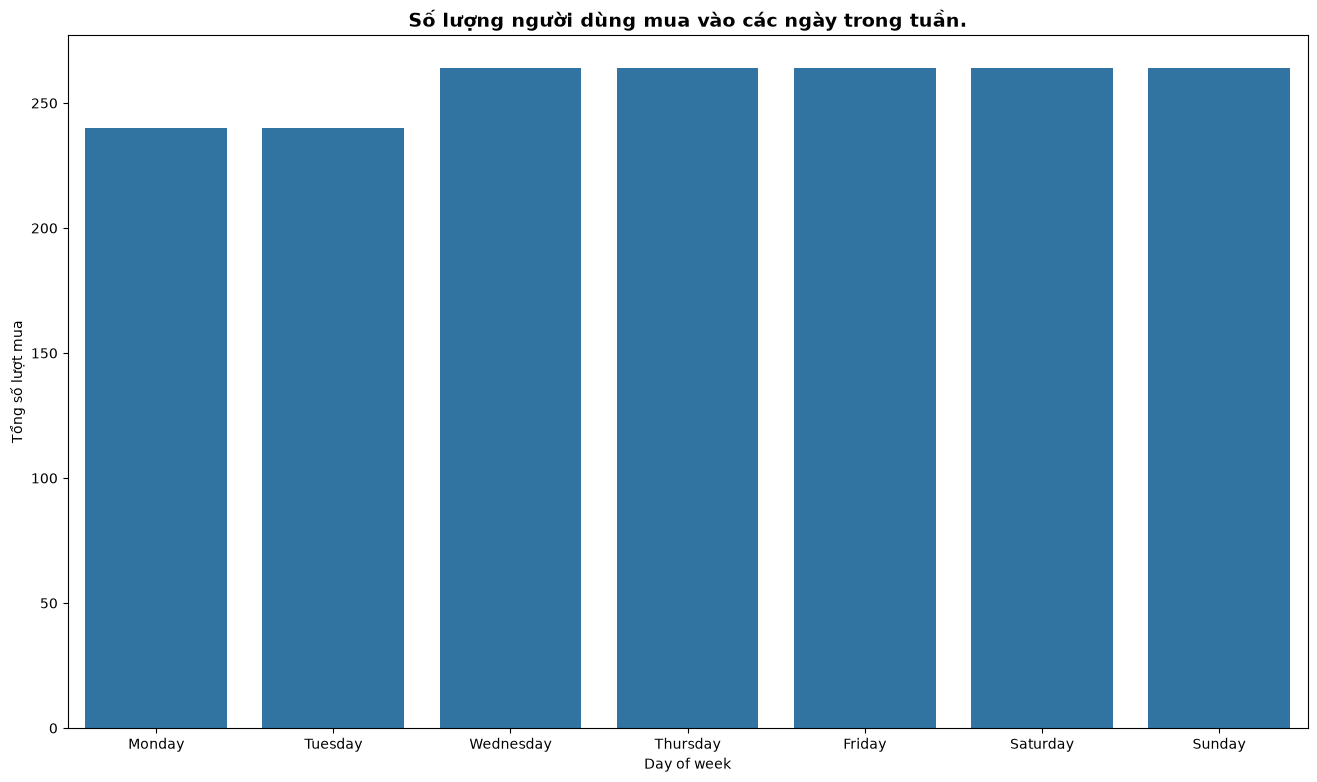

In [106]:
plt.figure(figsize=(16,9))
sns.barplot(day_of_week_sale,x='Day Of Week', y='TotalAmount_USD')
plt.title('Số lượng người dùng mua vào các ngày trong tuần.',fontsize = 14, fontweight = 'bold')
plt.xlabel('Day of week')
plt.ylabel('Tổng số lượt mua')
plt.show()